# Exploratory Data Analysis: Do Socioeconomic Factors Predict School Performance?

## Introduction
This project asks whether school performance, measured by a school's average ACT score, is predicted by socioeconomic factors. The ACT is a college admissions exam scored from 1 to 36. This notebook is the second of three: `education_data_preparation.ipynb` produced the clean data set, and `education_modeling.ipynb` fits the regression models.

The goal of the exploratory data analysis is to understand the clean data before modeling it:
- how each socioeconomic predictor relates to the average ACT score, and how the predictors relate to each other;
- how each variable is distributed, and whether there are outliers;
- whether charter and non-charter schools show the same relationships.

The data combine the [EdGap.org](https://www.edgap.org/) 2016 data (average ACT score and socioeconomic measures of the school's community) with school information from the [NCES Common Core of Data](https://nces.ed.gov/ccd/) (state, school type, school level and charter status), as described in the data preparation notebook.

# Import libraries
Import libraries for data handling, plotting, and later modeling.

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

# Load clean data
Load the clean data set that was exported at the end of the data preparation notebook. Each row is one high school.

In [ ]:
data_folder = '/Users/amruta/coursework/DATA_5100/education/data'

df = pd.read_csv(f'{data_folder}/education_clean.csv')

Preview the first rows to check that the data loaded correctly.

In [3]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


The data frame has the average ACT score (`average_act`), the five socioeconomic predictors, and the year, state, zip code, school type, school level and charter status of each school. The socioeconomic predictors have no missing values because they were imputed during data preparation.

# Exploratory data analysis

## Examine distributions and relationships

### Plot the correlation matrix of the numerical variables
The correlation matrix shows the linear relationship between every pair of numerical variables, from -1 (perfect negative relationship) to +1 (perfect positive relationship). It is used to look at the correlation between `average_act` and each predictor, and at the correlations among the predictors.

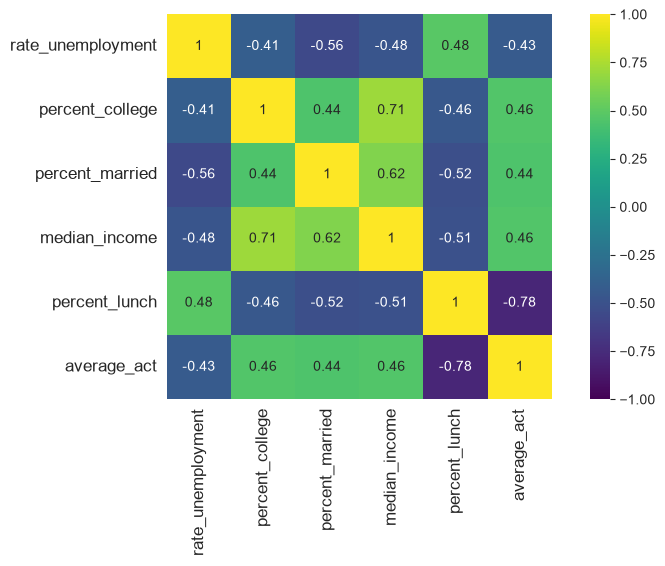

In [4]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'charter'
]

numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

- **Predictors and ACT:** `percent_lunch` has by far the strongest correlation with the average ACT score (-0.78): schools with a larger share of students on free or reduced lunch have lower scores. The other four predictors have weaker correlations of similar size (+0.46 for `percent_college` and `median_income`, +0.44 for `percent_married`, -0.43 for `rate_unemployment`).
- **Predictors and each other:** the predictors are also correlated with each other, most strongly `percent_college` with `median_income` (0.71) and `median_income` with `percent_married` (0.62). `rate_unemployment` is negatively correlated with `percent_married` (-0.56).
- **Consequence:** because the predictors overlap, not all of them are likely to be needed in a single model. This is examined in the modeling notebook.

### Make pair plots to explore relationships between the variables
A pair plot shows a scatter plot of every pair of variables with a regression line, and the distribution of each variable on the diagonal. The points are colored by charter status to see whether the relationships differ between groups of schools.

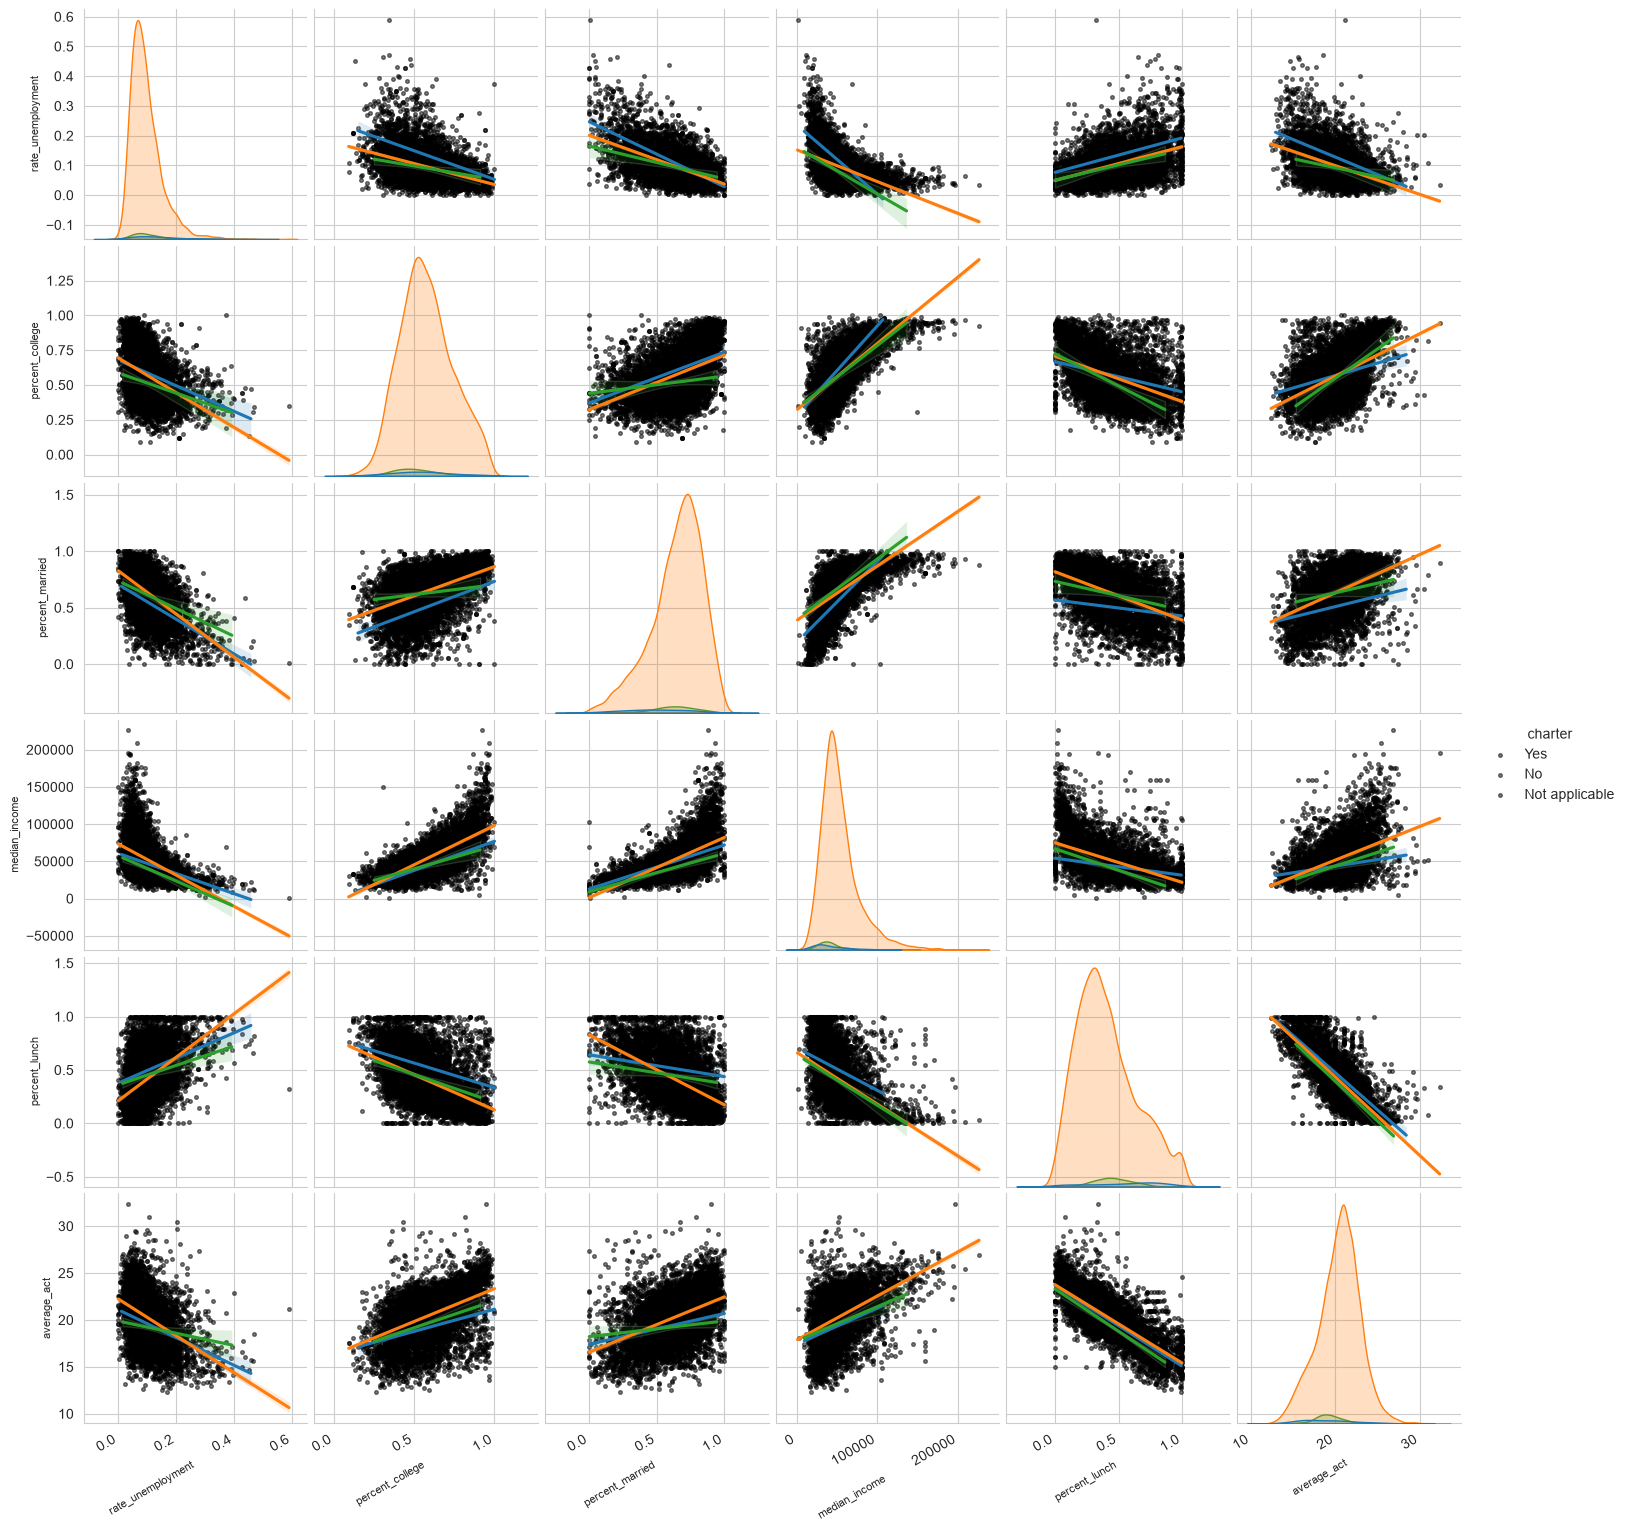

In [5]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    hue = 'charter',
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

The relationships between the predictors and `average_act` look roughly linear, and the scatter around each line is wide, apart from `percent_lunch`, whose relationship is the tightest. The regression lines of the charter groups have similar directions to the overall pattern, although their slopes differ somewhat. The charter and "Not applicable" groups are much smaller than the non-charter group, so their lines are less certain. The distributions on the diagonal show that median income and the unemployment rate are skewed to the right.

### Identify outliers
Outliers can be identified with the interquartile range (IQR), and they are also visible in box plots. Median income is on a very different scale than the other predictors, so two plots are made.

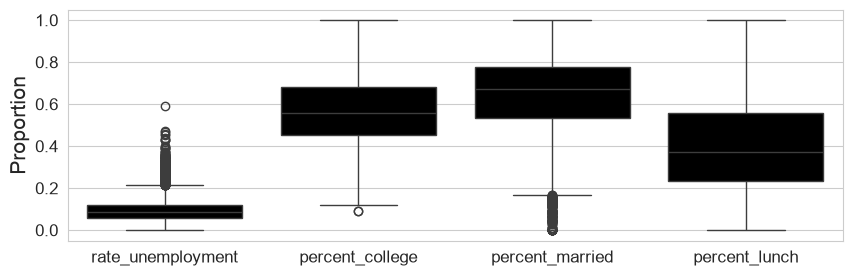

In [6]:
plt.figure(figsize = (10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data = df[fractions], color = 'k')

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

The box plots of the four proportion variables show the median, the middle half of the values and the points beyond the whiskers, which are the outliers.

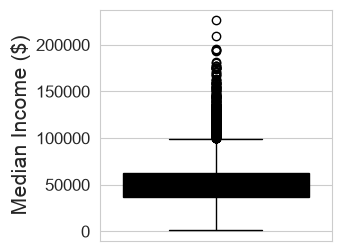

In [7]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['median_income'], color = 'k')

plt.ylabel('Median Income ($)', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

The box plot of median income shows many high-income outliers, which reflects a right-skewed distribution.

## Summary
1. The numerical predictors are related to `average_act`, and the relationships appear roughly linear. `percent_lunch` has the strongest relationship (correlation of -0.78).
2. The numerical predictors are correlated with each other, suggesting that not all predictors will be necessary in a model.
3. Some variables have skewed distributions, suggesting that transformations of the input variables might be useful.
4. There are outliers in `rate_unemployment`, `percent_college`, `percent_married` and `median_income`. None of them is obviously incorrect; they likely reflect skewed distributions. A transformation such as a log transformation could be considered when exploring different models.
5. The relationships are similar across charter and non-charter schools, but might be significantly different. This is tested in the modeling notebook.